# SQ1 — Mapping the Financial Landscape

**How do financial profiles differ across income groups, and do the data-driven clusters actually match the World Bank income labels?**

Team 2 · Introduction to Data Analytics, HWR Berlin · SoSe 2026 

This notebook builds the country×year panel from the raw World Bank files and produces the four SQ1 figures (saved to `charts/`). Run the cells top to bottom.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ── Paths ─────────────────────────────────────────────────────────────────
# DATA_DIR auto-detects whether you run locally (inside the repo) or in Colab.
#   • Local repo layout (notebook two levels under the root) → ../../data
#   • Google Colab: upload DataSheet_Main.csv (+ Metadata_Country.csv);
#     they land in /content, which the last candidate below picks up.
_CANDIDATES = [Path("../../data"), Path("data"), Path("/content/data"), Path("/content")]
DATA_DIR = next((p for p in _CANDIDATES if (p / "DataSheet_Main.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "DataSheet_Main.csv not found. In Colab, upload it first "
        "(Files panel on the left, or a files.upload() cell), then run this cell again. "
        "Locally, set DATA_DIR to the folder holding the World Bank CSVs.")
print("Using DATA_DIR =", DATA_DIR)

OUT_DIR = Path("charts")           # figures are saved here, ready for the slides
OUT_DIR.mkdir(exist_ok=True)

# ── Constants ─────────────────────────────────────────────────────────────
CHANNELS      = ["domestic_credit", "broad_money", "bank_branches", "atms", "fdi_inflows"]
INCOME_ORDER  = ["Low income", "Lower middle income", "Upper middle income", "High income"]
CLUSTER_NAMES = ["Cluster 1 (shallow)", "Cluster 2 (medium)",
                 "Cluster 3 (deep)", "Cluster 4 (extreme)"]

# ── SQ1 chart palette (matches the slide deck) ─────────────────────────────
INK, TEAL, ACCENT = "#1d2433", "#2f6f8f", "#c2603f"
SEQ = LinearSegmentedColormap.from_list("seq", ["#eef3f6", "#9cc3d5", "#2f6f8f", "#173f52"])
INCOME_COLORS = {"Low income": "#c2603f", "Lower middle income": "#e0a458",
                 "Upper middle income": "#9cc3d5", "High income": "#2f6f8f"}

plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})

Using DATA_DIR = /content


## 1 · Load the data and build the panel

Reshape the World Bank files into one row per **country × year**, then attach each country's region and income group. The income label is merged on `Country Code` (canonical) and aggregates like *World* are dropped.

In [2]:
# Indicator code → short name (9 financial indicators; GDP growth comes from the GDP file)
CODE_TO_NAME = {
    "FS.AST.PRVT.GD.ZS":    "domestic_credit",
    "FM.LBL.BMNY.GD.ZS":    "broad_money",
    "FB.CBK.BRCH.P5":       "bank_branches",
    "FB.ATM.TOTL.P5":       "atms",
    "BX.KLT.DINV.WD.GD.ZS": "fdi_inflows",
    "FR.INR.LNDP":          "interest_spread",
    "FB.AST.NPER.ZS":       "nonperforming_loans",
    "CM.MKT.LCAP.GD.ZS":    "market_cap",
    "NY.GDP.DEFL.KD.ZG.AD": "inflation",
    "NY.GDP.MKTP.KD.ZG":    "gdp_growth",    # lives in DataSheet_GDP.csv
}

# World Bank files carry 4 header rows of metadata → skiprows=4
main    = pd.read_csv(DATA_DIR / "DataSheet_Main.csv", skiprows=4, encoding="utf-8-sig")
country = pd.read_csv(DATA_DIR / "Metadata_Country.csv", encoding="utf-8-sig")

# GDP growth sits in a separate, more up-to-date file. SQ1 doesn't use it, but we
# fold it in so this panel matches the team's shared panel.
gdp_path = DATA_DIR / "DataSheet_GDP.csv"
gdp = pd.read_csv(gdp_path, skiprows=4, encoding="utf-8-sig") if gdp_path.exists() else None

# 1) keep only our indicators
fin_codes = [c for c, n in CODE_TO_NAME.items() if n != "gdp_growth"]
frames = [main[main["Indicator Code"].isin(fin_codes)]]
if gdp is not None:
    frames.append(gdp[gdp["Indicator Code"] == "NY.GDP.MKTP.KD.ZG"])
raw = pd.concat(frames, ignore_index=True)

# 2) reshape wide → long → panel (melt, then pivot): one row per country × year
year_cols = [c for c in raw.columns if c.isdigit()]
long = raw.melt(id_vars=["Country Name", "Country Code", "Indicator Code"],
                value_vars=year_cols, var_name="Year", value_name="Value")
long["Year"]  = long["Year"].astype(int)
long["Value"] = pd.to_numeric(long["Value"], errors="coerce")

df_panel = (long.pivot_table(index=["Country Name", "Country Code", "Year"],
                             columns="Indicator Code", values="Value")
                .reset_index()
                .rename(columns=CODE_TO_NAME))
df_panel = df_panel[df_panel["Year"].between(2004, 2021)]

# 3) attach Region + IncomeGroup on the country code, drop aggregates (World etc.)
df_panel = df_panel.merge(country[["Country Code", "Region", "IncomeGroup"]],
                          on="Country Code", how="left")
df_panel = df_panel[df_panel["IncomeGroup"].notna()].copy()
df_panel["IncomeGroup"] = pd.Categorical(df_panel["IncomeGroup"],
                                         categories=INCOME_ORDER, ordered=True)

print("Panel:", df_panel.shape[0], "rows ·", df_panel["Country Name"].nunique(), "countries")
df_panel.head(3)

Panel: 3813 rows · 215 countries


,Country Name,Country Code,Year,fdi_inflows,market_cap,nonperforming_loans,atms,bank_branches,broad_money,interest_spread,domestic_credit,inflation,gdp_growth,Region,IncomeGroup
0,Afghanistan,AFG,2004,3.577104,NaN,NaN,0.02,0.37,NaN,NaN,NaN,11.271432,1.414118,South Asia,Low income
1,Afghanistan,AFG,2005,4.368673,NaN,NaN,0.06,0.58,NaN,NaN,NaN,10.912774,11.229715,South Asia,Low income
2,Afghanistan,AFG,2006,3.413773,NaN,NaN,0.12,0.92,23.343865,NaN,4.842857,7.199751,5.357403,South Asia,Low income


## 2 · Part 1 — Financial profile per income group

The descriptive sanity check: do the financial indicators rise with income? We take the **median** of each indicator per income group — median, not mean, because a few financial hubs would drag the mean up.

In [3]:
# Median financial profile per income group
profile_by_income = df_panel.groupby("IncomeGroup")[CHANNELS].median().reindex(INCOME_ORDER)
profile_by_income.round(1)

/tmp/ipykernel_14921/318321493.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  profile_by_income = df_panel.groupby("IncomeGroup")[CHANNELS].median().reindex(INCOME_ORDER)


,domestic_credit,broad_money,bank_branches,atms,fdi_inflows
IncomeGroup,,,,,
Low income,10.8,22.9,2.2,1.8,2.7
Lower middle income,23.2,39.4,6.3,11.2,2.2
Upper middle income,42.4,49.7,13.2,36.6,3.5
High income,81.8,77.5,23.8,67.6,3.5


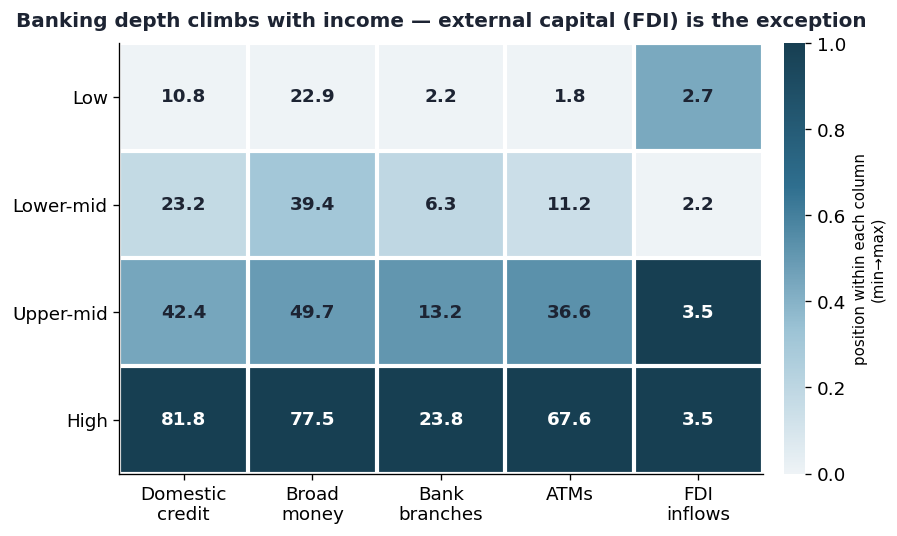

In [4]:
# ── Chart 1 · profile heatmap ──────────────────────────────────────────────
med  = profile_by_income
norm = (med - med.min()) / (med.max() - med.min())     # colour scaled within each column
labels5 = ["Domestic\ncredit", "Broad\nmoney", "Bank\nbranches", "ATMs", "FDI\ninflows"]
short   = ["Low", "Lower-mid", "Upper-mid", "High"]

fig, ax = plt.subplots(figsize=(7.6, 4.6))
im = ax.imshow(norm.values, cmap=SEQ, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(labels5)
ax.set_yticks(range(4)); ax.set_yticklabels(short)
for i in range(4):
    for j in range(5):
        v = med.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontweight="bold",
                color="white" if norm.values[i, j] > 0.55 else INK)
ax.set_title("Banking depth climbs with income — external capital (FDI) is the exception",
             fontsize=12, fontweight="bold", pad=10, color=INK)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cb.set_label("position within each column\n(min→max)", fontsize=9); cb.outline.set_visible(False)
ax.set_xticks(np.arange(-.5, 5, 1), minor=True); ax.set_yticks(np.arange(-.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2.5); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_profile_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 3 · Part 2 — Do the data rebuild the income tiers? (clustering)

Hide the income labels and let **k-means** group countries on their financial fingerprint alone. Two deliberate choices: **standardize** first (the indicators are on very different scales) and **k = 4** (to test directly against the four income groups).

In [5]:
# One row per country = its 2004–2021 average on the 5 indicators
profil = df_panel.groupby("Country Name")[CHANNELS].mean()
profil["IncomeGroup"] = (df_panel.drop_duplicates("Country Name")
                                 .set_index("Country Name")["IncomeGroup"])

# Drop countries missing > 2 of 5 indicators (mostly poorer ones — an honest limit),
# then fill the few remaining gaps with the column median so k-means can run.
before = len(profil)
profil = profil[profil[CHANNELS].isna().sum(axis=1) <= 2]
profil[CHANNELS] = profil[CHANNELS].fillna(profil[CHANNELS].median())
print(f"Countries: {before} -> {len(profil)} after dropping sparse rows")

# Standardize (different scales → required) then k-means, k = 4
X  = StandardScaler().fit_transform(profil[CHANNELS])
km = KMeans(n_clusters=4, random_state=0, n_init=10).fit(X)
profil["cluster_id"] = km.labels_

# Relabel clusters by depth: Cluster 1 (shallowest) → Cluster 4 (deepest)
order_by_depth = profil.groupby("cluster_id")["domestic_credit"].mean().sort_values().index
id_to_name = {cid: CLUSTER_NAMES[i] for i, cid in enumerate(order_by_depth)}
profil["cluster"] = pd.Categorical(profil["cluster_id"].map(id_to_name),
                                   categories=CLUSTER_NAMES, ordered=True)

crosstab = pd.crosstab(profil["cluster"], profil["IncomeGroup"]).reindex(CLUSTER_NAMES)[INCOME_ORDER]
print("\nCross-tab (cluster x income):"); print(crosstab)
print("\nMean financial profile per cluster:")
print(profil.groupby("cluster")[CHANNELS].mean().round(1))
print("\nCluster 4 members:",
      sorted(profil.index[profil["cluster"] == CLUSTER_NAMES[3]].tolist()))
print("High-income countries in the shallowest cluster:",
      sorted(profil.index[(profil["cluster"] == CLUSTER_NAMES[0]) &
                          (profil["IncomeGroup"] == "High income")].tolist()))

Countries: 215 -> 186 after dropping sparse rows

Cross-tab (cluster x income):
IncomeGroup          Low income  Lower middle income  Upper middle income  \
cluster                                                                     
Cluster 1 (shallow)          23                   38                   22   
Cluster 2 (medium)            1                   15                   26   
Cluster 3 (deep)              0                    1                    2   
Cluster 4 (extreme)           0                    0                    0   

IncomeGroup          High income  
cluster                           
Cluster 1 (shallow)            2  
Cluster 2 (medium)            39  
Cluster 3 (deep)              15  
Cluster 4 (extreme)            2  

Mean financial profile per cluster:
                     domestic_credit  broad_money  bank_branches   atms  \
cluster                                                                   
Cluster 1 (shallow)             21.0         36.5           

/tmp/ipykernel_14921/1333367640.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(profil.groupby("cluster")[CHANNELS].mean().round(1))


/tmp/ipykernel_14921/3597986772.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = profil.groupby("cluster")[CHANNELS].mean().reindex(CLUSTER_NAMES)


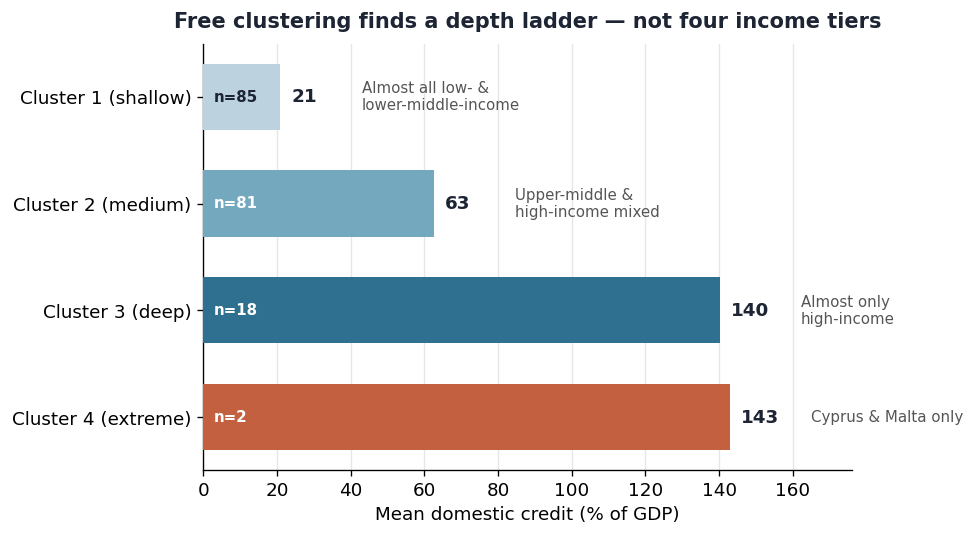

In [6]:
# ── Chart 2 · depth ladder ─────────────────────────────────────────────────
means = profil.groupby("cluster")[CHANNELS].mean().reindex(CLUSTER_NAMES)
sizes = profil["cluster"].value_counts().reindex(CLUSTER_NAMES)
dc    = means["domestic_credit"]
who   = ["Almost all low- &\nlower-middle-income", "Upper-middle &\nhigh-income mixed",
         "Almost only\nhigh-income", "Cyprus & Malta only"]
colors = ["#bcd3df", "#74a8bf", "#2f6f8f", "#c2603f"]

fig, ax = plt.subplots(figsize=(8.2, 4.6)); y = np.arange(4)
ax.barh(y, dc.values, color=colors, height=0.62, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(CLUSTER_NAMES); ax.invert_yaxis()
ax.set_xlabel("Mean domestic credit (% of GDP)"); ax.set_xlim(0, 176)
for i, (v, n, w) in enumerate(zip(dc.values, sizes.values, who)):
    ax.text(v + 3, i, f"{v:.0f}", va="center", fontweight="bold", color=INK)
    ax.text(3, i, f"n={n}", va="center", fontsize=9, fontweight="bold",
            color="white" if v > 40 else INK)
    ax.text(v + 22, i, w, va="center", fontsize=9, color="#555")
ax.set_title("Free clustering finds a depth ladder — not four income tiers",
             fontsize=12.5, fontweight="bold", pad=10, color=INK)
ax.grid(axis="x", color="#e6e6e6", zorder=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_depth_ladder.png", dpi=200, bbox_inches="tight")
plt.show()

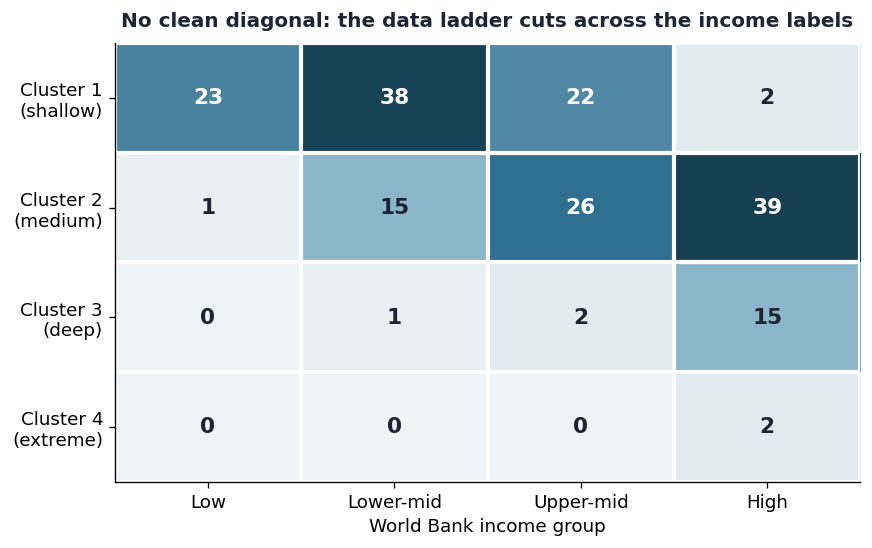

In [7]:
# ── Chart 3 · cluster x income cross-tab ───────────────────────────────────
short_inc     = ["Low", "Lower-mid", "Upper-mid", "High"]
names_wrapped = [n.replace(" (", "\n(") for n in CLUSTER_NAMES]

fig, ax = plt.subplots(figsize=(7.4, 4.7))
im = ax.imshow(crosstab.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(short_inc)
ax.set_yticks(range(4)); ax.set_yticklabels(names_wrapped)
mx = crosstab.values.max()
for i in range(4):
    for j in range(4):
        v = crosstab.values[i, j]
        ax.text(j, i, int(v), ha="center", va="center", fontweight="bold", fontsize=13,
                color="white" if v > mx * 0.5 else INK)
ax.set_xlabel("World Bank income group")
ax.set_title("No clean diagonal: the data ladder cuts across the income labels",
             fontsize=12, fontweight="bold", pad=10, color=INK)
ax.set_xticks(np.arange(-.5, 4, 1), minor=True); ax.set_yticks(np.arange(-.5, 4, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2.5); ax.tick_params(which="minor", length=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_crosstab_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

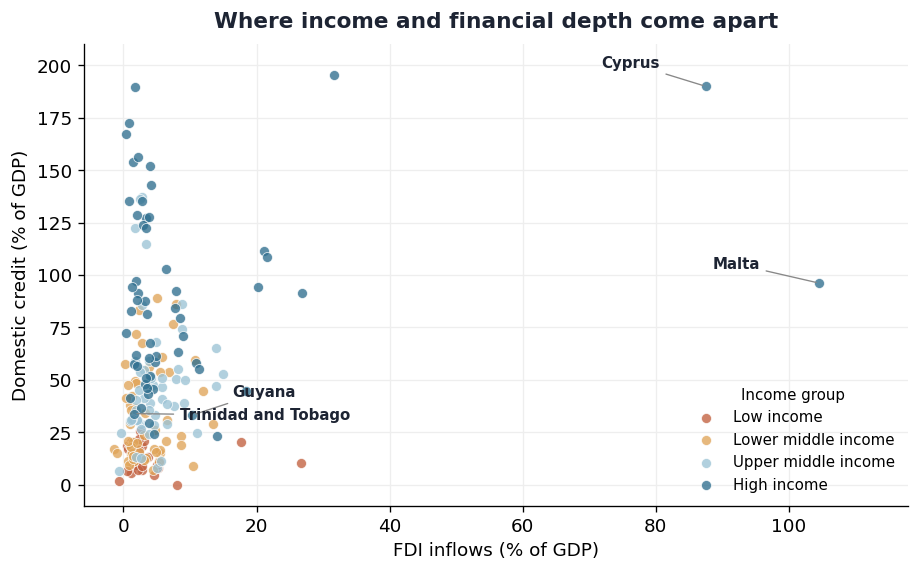

In [8]:
# ── Chart 4 · outliers (FDI vs domestic credit) ────────────────────────────
fig, ax = plt.subplots(figsize=(7.8, 4.9))
for ig in INCOME_ORDER:
    sub = profil[profil["IncomeGroup"] == ig]
    ax.scatter(sub["fdi_inflows"], sub["domestic_credit"], s=36, alpha=0.78,
               color=INCOME_COLORS[ig], label=ig, edgecolor="white", linewidth=0.5, zorder=3)
for name, dx, dy, ha in [("Cyprus", -7, 9, "right"), ("Malta", -9, 7, "right"),
                         ("Guyana", 6, 9, "left"), ("Trinidad and Tobago", 7, -3, "left")]:
    if name in profil.index:
        xv, yv = profil.loc[name, "fdi_inflows"], profil.loc[name, "domestic_credit"]
        ax.annotate(name, (xv, yv), xytext=(xv + dx, yv + dy), fontsize=9, fontweight="bold",
                    color=INK, ha=ha, arrowprops=dict(arrowstyle="-", color="#888", lw=0.8))
ax.set_xlabel("FDI inflows (% of GDP)"); ax.set_ylabel("Domestic credit (% of GDP)")
ax.set_title("Where income and financial depth come apart",
             fontsize=13, fontweight="bold", pad=10, color=INK)
ax.legend(frameon=False, fontsize=9, loc="lower right", title="Income group", title_fontsize=9)
ax.grid(color="#eee", zorder=0); ax.set_xlim(-6, 118); ax.set_ylim(-10, 210)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_outliers_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

## 4 · Takeaways

- **Banking depth climbs with income; FDI is the exception** — it is flat across all four groups.
- Free clustering finds a **ladder of financial depth (≈186 countries), not four income tiers**: the cross-tab drifts the right way but is smeared, not diagonal — upper-middle income splits across three clusters.
- **Outliers:** Cyprus & Malta form their own micro-cluster (FDI ≈ 90–100% of GDP); Guyana & Trinidad and Tobago are high-income but among the shallowest. No low-income country looks financially rich — depth can lag income, never lead it.

